
================ BLAND–ALTMAN ANALYSIS ================

                Formulation  Predicted DL  Experimental mean  Experimental SD  Difference (Exp − Pred)
 Betamethasone-loaded CsNPs         33.44              34.93             3.21                     1.49
 Ciprofloxacin-loaded CsNPs         34.18              35.75             1.48                     1.57
Betamethasone-loaded TMCNPs         36.28              36.62             2.30                     0.34
Ciprofloxacin-loaded TMCNPs         23.55              23.80             1.84                     0.25

--------------------------------------------------------
Number of formulations:              4
Replicates per formulation (n):      3
Mean bias:                            0.91 percentage points
Between-formulation variance:         0.51
Pooled within-formulation variance:  5.29
Multiplier (1 − 1/n):                 0.667
Variance-adjusted total variance:     4.04
Variance-adjusted total SD:           2.01
Lower 95% LOA: 

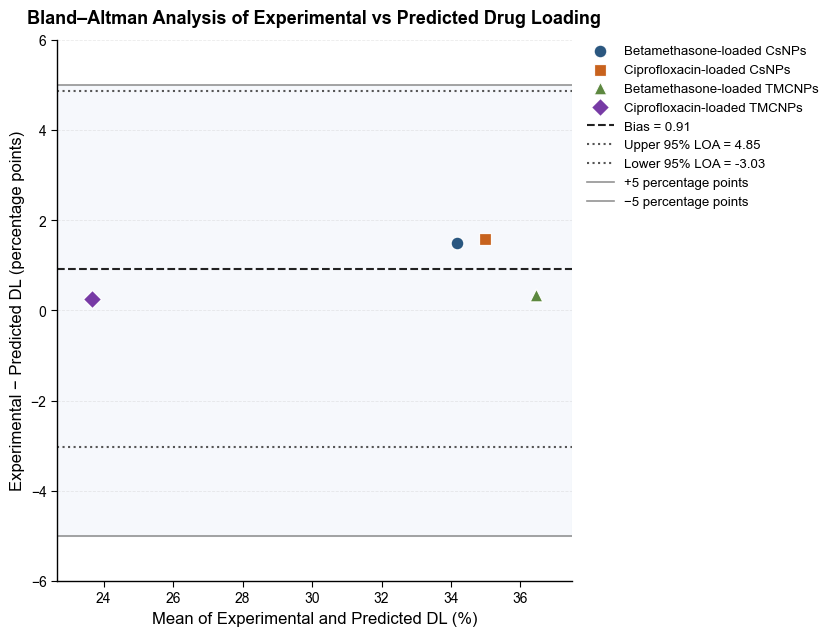


Results saved to:
Bland_Altman_DL_summary_statistics.xlsx


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. DATA
# ============================================================


data = {
    "Betamethasone-loaded CsNPs": {
        "predicted": 33.44,
        "experimental_mean": 34.93,
        "experimental_sd": 3.21,
        "n": 3
    },

    "Ciprofloxacin-loaded CsNPs": {
        "predicted": 34.18,
        "experimental_mean": 35.75,
        "experimental_sd": 1.48,
        "n": 3
    },

    "Betamethasone-loaded TMCNPs": {
        "predicted": 36.28,
        "experimental_mean": 36.62,
        "experimental_sd": 2.30,
        "n": 3
    },

    "Ciprofloxacin-loaded TMCNPs": {
        "predicted": 23.55,
        "experimental_mean": 23.80,
        "experimental_sd": 1.84,
        "n": 3
    }
}


# ============================================================
# 2. SETTINGS
# ============================================================

N = 3

# Prespecified acceptable agreement margin
# ±5 percentage points of drug loading
MARGIN = 5.0

# Bland–Altman multiplier
Z = 1.96


# ============================================================
# 3. PREPARE DATA
# ============================================================

results = []

for formulation, values in data.items():

    predicted = values["predicted"]
    experimental_mean = values["experimental_mean"]
    experimental_sd = values["experimental_sd"]
    n = values["n"]

    # Difference between experimental mean and prediction
    difference = experimental_mean - predicted

    # Average of experimental and predicted values
    mean_value = (experimental_mean + predicted) / 2

    results.append({
        "Formulation": formulation,
        "Predicted DL": predicted,
        "Experimental mean": experimental_mean,
        "Experimental SD": experimental_sd,
        "n": n,
        "Mean value": mean_value,
        "Difference (Exp − Pred)": difference,
        "Within-formulation variance":
            experimental_sd ** 2
    })


df = pd.DataFrame(results)


# ============================================================
# 4. OVERALL BIAS
# ============================================================

bias = df["Difference (Exp − Pred)"].mean()


# ============================================================
# 5. BETWEEN-FORMULATION VARIANCE
# ============================================================
#
# Sample variance of the four formulation-level differences.
#
# ddof=1 is used because this is a sample variance.
#
# ============================================================

between_variance = np.var(
    df["Difference (Exp − Pred)"],
    ddof=1
)


# ============================================================
# 6. POOLED WITHIN-FORMULATION VARIANCE
# ============================================================
#
# Since each formulation has n = 3 replicates, the pooled
# within-formulation variance is calculated using the
# replicate-level degrees of freedom.
#
# pooled within variance =
# sum((n_i - 1) * SD_i^2) / sum(n_i - 1)
#
# ============================================================

numerator = 0
denominator = 0

for _, row in df.iterrows():

    n_i = row["n"]
    sd_i = row["Experimental SD"]

    numerator += (
        (n_i - 1) * sd_i ** 2
    )

    denominator += (
        n_i - 1
    )


pooled_within_variance = (
    numerator / denominator
)


# ============================================================
# 7. VARIANCE-ADJUSTED TOTAL VARIANCE
# ============================================================
#
# The observed formulation-level means contain only a fraction
# of the underlying within-formulation variance.
#
# Adjustment:
#
# Total variance =
#     between variance
#     + (1 - 1/n) × pooled within variance
#
# For n = 3:
#
#     1 - 1/3 = 0.6667
#
# ============================================================

multiplier = 1 - (1 / N)

total_variance = (
    between_variance
    + multiplier * pooled_within_variance
)

total_sd = np.sqrt(total_variance)


# ============================================================
# 8. 95% LIMITS OF AGREEMENT
# ============================================================

loa_lower = bias - Z * total_sd
loa_upper = bias + Z * total_sd


# ============================================================
# 9. PRINT RESULTS
# ============================================================

print(
    "\n================ BLAND–ALTMAN ANALYSIS ================\n"
)

print(
    df[
        [
            "Formulation",
            "Predicted DL",
            "Experimental mean",
            "Experimental SD",
            "Difference (Exp − Pred)"
        ]
    ].to_string(index=False)
)

print("\n--------------------------------------------------------")

print(
    f"Number of formulations:              {len(df)}"
)

print(
    f"Replicates per formulation (n):      {N}"
)

print(
    f"Mean bias:                            {bias:.2f} percentage points"
)

print(
    f"Between-formulation variance:         {between_variance:.2f}"
)

print(
    f"Pooled within-formulation variance:  {pooled_within_variance:.2f}"
)

print(
    f"Multiplier (1 − 1/n):                 {multiplier:.3f}"
)

print(
    f"Variance-adjusted total variance:     {total_variance:.2f}"
)

print(
    f"Variance-adjusted total SD:           {total_sd:.2f}"
)

print(
    f"Lower 95% LOA:                        {loa_lower:.2f}"
)

print(
    f"Upper 95% LOA:                        {loa_upper:.2f}"
)

print(
    f"Prespecified agreement margin:        ±{MARGIN:.1f} percentage points"
)


# ============================================================
# 10. CHECK AGAINST ±5 AGREEMENT MARGIN
# ============================================================

loa_within_margin = (
    loa_lower >= -MARGIN
    and loa_upper <= MARGIN
)

print(
    "\nAgreement within ±5 percentage points: "
    f"{'YES' if loa_within_margin else 'NO'}"
)


# ============================================================
# ============================================================
# 11. BLAND–ALTMAN PLOT
# ============================================================

# Publication-style plotting settings
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9.5,
    "axes.linewidth": 1.0,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "savefig.dpi": 600,
    "savefig.bbox": "tight"
})

fig, ax = plt.subplots(figsize=(8.5, 6.5))

markers = ["o", "s", "^", "D"]
point_colors = ["#1F4E79", "#C55A11", "#548235", "#7030A0"]

for marker, color, (_, row) in zip(
    markers,
    point_colors,
    df.iterrows()
):
    ax.scatter(
        row["Mean value"],
        row["Difference (Exp − Pred)"],
        s=85,
        marker=marker,
        facecolor=color,
        edgecolor="white",
        linewidth=0.9,
        alpha=0.95,
        label=row["Formulation"],
        zorder=5
    )

# ------------------------------------------------------------
# Bias
# ------------------------------------------------------------

ax.axhline(
    bias,
    color="#222222",
    linestyle="--",
    linewidth=1.5,
    label=f"Bias = {bias:.2f}",
    zorder=2
)

# ------------------------------------------------------------
# 95% limits of agreement
# ------------------------------------------------------------

ax.axhline(
    loa_upper,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label=f"Upper 95% LOA = {loa_upper:.2f}",
    zorder=2
)

ax.axhline(
    loa_lower,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label=f"Lower 95% LOA = {loa_lower:.2f}",
    zorder=2
)

# ------------------------------------------------------------
# ±5 percentage-point agreement limits
# ------------------------------------------------------------

ax.axhline(
    MARGIN,
    color="#888888",
    linestyle="-",
    linewidth=1.2,
    alpha=0.9,
    label=f"+{MARGIN:.0f} percentage points",
    zorder=1
)

ax.axhline(
    -MARGIN,
    color="#888888",
    linestyle="-",
    linewidth=1.2,
    alpha=0.9,
    label=f"−{MARGIN:.0f} percentage points",
    zorder=1
)

# ------------------------------------------------------------
# Optional visual emphasis of the prespecified agreement band
# ------------------------------------------------------------

ax.axhspan(
    -MARGIN,
    MARGIN,
    color="#D9E2F3",
    alpha=0.22,
    zorder=0
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Mean of Experimental and Predicted DL (%)",
    fontsize=12
)

ax.set_ylabel(
    "Experimental − Predicted DL (percentage points)",
    fontsize=12
)

ax.set_title(
    "Bland–Altman Analysis of Experimental vs Predicted Drug Loading",
    fontsize=13,
    fontweight="bold",
    pad=12
)

# ------------------------------------------------------------
# Axes and grid styling
# ------------------------------------------------------------

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.25
)

ax.grid(
    axis="x",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    direction="out",
    length=4,
    width=0.8
)

# Add a small margin around the data for a cleaner layout
ax.margins(x=0.08, y=0.10)

# Keep the legend clean and outside the plotting region
ax.legend(
    bbox_to_anchor=(1.02, 1.00),
    loc="upper left",
    frameon=False,
    borderaxespad=0
)

fig.tight_layout()

# ------------------------------------------------------------
# Save plot
# ------------------------------------------------------------

fig.savefig(
    "Bland_Altman_DL_summary_statistics.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    "Bland_Altman_DL_summary_statistics.tiff",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. SAVE PLOT
# ============================================================

# 13. SAVE RESULTS TO EXCEL
# ============================================================

summary_results = pd.DataFrame({
    "Statistic": [
        "Number of formulations",
        "Replicates per formulation (n)",
        "Mean bias",
        "Between-formulation variance",
        "Pooled within-formulation variance",
        "Multiplier (1 − 1/n)",
        "Variance-adjusted total variance",
        "Variance-adjusted total SD",
        "Lower 95% LOA",
        "Upper 95% LOA",
        "Agreement margin",
        "LOA within ±5"
    ],
    "Value": [
        len(df),
        N,
        bias,
        between_variance,
        pooled_within_variance,
        multiplier,
        total_variance,
        total_sd,
        loa_lower,
        loa_upper,
        MARGIN,
        loa_within_margin
    ]
})


with pd.ExcelWriter(
    "Bland_Altman_DL_summary_statistics.xlsx"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Formulation_Data",
        index=False
    )

    summary_results.to_excel(
        writer,
        sheet_name="BA_Summary",
        index=False
    )


print(
    "\nResults saved to:"
)

print(
    "Bland_Altman_DL_summary_statistics.xlsx"
)
